|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[16] Softmax probability distributions</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50,
})

# **Part 1: Softmax in numpy and PyTorch**

In [3]:
# the list of numbers
z = [1,1.1,2,3,5,6,6.1]

# compute the softmax result
num = np.exp(z)
den = np.sum( np.exp(z) )
sm = num / den

print(sm)
print(np.sum(sm))

[0.00263681 0.00291413 0.0071676  0.01948356 0.1439651  0.39133772
 0.43249507]
1.0


In [4]:
zTorch = torch.tensor(z,dtype=torch.float32)

# using a function
zTorch_sm = F.softmax(zTorch,dim=-1)
zTorch_sm

tensor([0.0026, 0.0029, 0.0072, 0.0195, 0.1440, 0.3913, 0.4325])

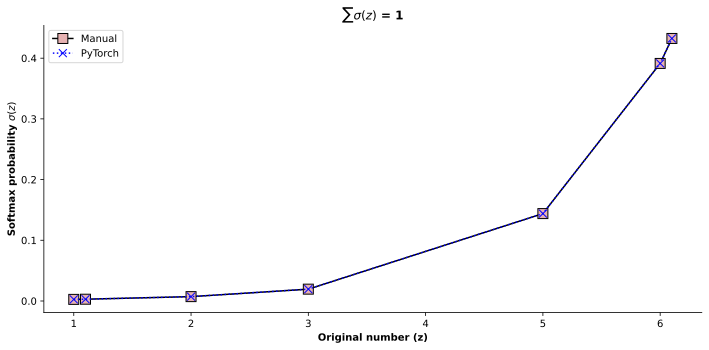

In [5]:
# compare
plt.figure(figsize=(10,5))

plt.plot(z,sm,'ks-',markerfacecolor=[.9,.7,.7],markersize=10,label='Manual')
plt.plot(z,zTorch_sm,'bx:',markersize=8,label='PyTorch')
plt.legend()

plt.gca().set(xlabel='Original number (z)',ylabel='Softmax probability $\\sigma (z)$',
              title='$\\sum\\sigma (z)$ = %g' %np.sum(sm))

plt.tight_layout()
plt.savefig('ch4_proj16_part1.png')
plt.show()

# **Part 2: Temperature**

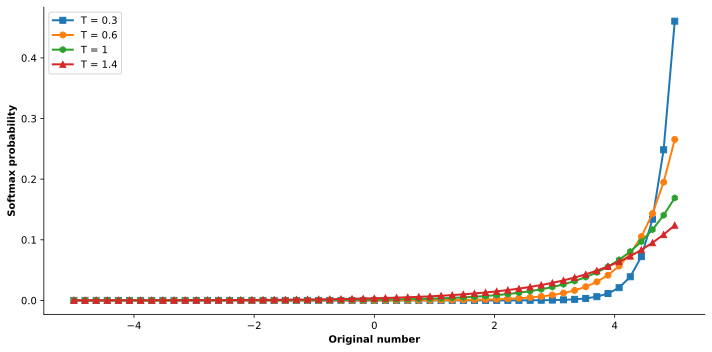

In [6]:
x = torch.linspace(-5,5,55)

shapes = 'soh^'

plt.figure(figsize=(10,5))
for i,temp in enumerate([.3,.6,1,1.4]):
  sm = F.softmax(x/temp,dim=-1)
  plt.plot(x,sm,shapes[i]+'-',linewidth=2,label='T = %g' %temp)

plt.legend()
plt.gca().set(xlabel='Original number',ylabel='Softmax probability')
# plt.yscale('log') # FYI

plt.tight_layout()
plt.savefig('ch4_proj16_part2.png')
plt.show()

# **Part 3: Softmax of LLM output logits**

In [7]:
# load pretrained GPT-2 model and tokenizer
gpt2_small = AutoModelForCausalLM.from_pretrained('gpt2')
gpt2_large = AutoModelForCausalLM.from_pretrained('gpt2-large')

# set to eval mode
gpt2_small.eval()
gpt2_large.eval()

# and the tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [8]:
print(f'GPT-2-small has {gpt2_small.num_parameters():,} parameters.')
print(f'GPT-2-large has {gpt2_large.num_parameters():,} parameters.')

GPT-2-small has 124,439,808 parameters.
GPT-2-large has 774,030,080 parameters.


In [9]:
txt = 'It was a dark and stormy'
tokens = tokenizer.encode(txt,return_tensors='pt') # pt = PyTorch
tokens

tensor([[1026,  373,  257, 3223,  290, 6388,   88]])

In [10]:
print(f'The text comprises {tokens.shape[1]} tokens.\n')

for t in tokens[0]:
  print(f'{t:5} is "{tokenizer.decode(t)}"')

The text comprises 7 tokens.

 1026 is "It"
  373 is " was"
  257 is " a"
 3223 is " dark"
  290 is " and"
 6388 is " storm"
   88 is "y"


In [11]:
# forward pass through the model
outputs = gpt2_small(tokens)
outputs

CausalLMOutputWithCrossAttentions(loss=None, logits=tensor([[[ -37.0890,  -36.4550,  -40.3287,  ...,  -45.2598,  -43.0251,
           -37.6605],
         [-120.1124, -119.2538, -125.9656,  ..., -126.5557, -123.9600,
          -123.0143],
         [-115.5612, -113.6851, -118.5185,  ..., -122.3477, -118.8637,
          -115.7403],
         ...,
         [ -95.5841,  -92.1288,  -98.0233,  ..., -100.4968,  -96.3200,
           -96.0847],
         [ -63.8668,  -62.5591,  -67.8027,  ...,  -77.6469,  -70.6219,
           -65.7388],
         [-114.5010, -112.2047, -120.4313,  ..., -124.7593, -121.1788,
          -116.3877]]], grad_fn=<UnsafeViewBackward0>), past_key_values=DynamicCache(layers=[DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer]), hidden_states=None, attentions=None, cross_attentions=None)

In [12]:
outputs.logits.shape

torch.Size([1, 7, 50257])

In [13]:
logits = outputs.logits[0,-1,:].detach()
logits_sm = F.softmax(logits,dim=-1)
logits.shape

torch.Size([50257])

In [14]:
print(f'The sum of the raw logits is {logits.sum():.3f}')
print(f'The sum of the softmax logits is {logits_sm.sum():.3f}')

The sum of the raw logits is -6054440.500
The sum of the softmax logits is 1.000


In [15]:
# plot the raw and softmax logits
_,axs = plt.subplots(1,3,figsize=(12,3))

axs[0].plot(logits,'ks',markerfacecolor=[.9,.7,.7,.3])
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',
           ylabel='Output logits',title='A) All final token logits')

axs[1].plot(logits_sm,'o',markerfacecolor=[.7,.9,.7,.3])
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',
           ylabel='Probabilities',title='B) Softmax probabilities')

axs[2].plot(logits,logits_sm,'^',markerfacecolor=[.7,.7,.9,.7])
axs[2].set(xlabel='"Raw" logits',ylabel='Softmax logits',
           title='C) Logits by probabilities')

plt.tight_layout()
plt.savefig('ch4_proj16_part3.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [16]:
# find the maximum
max_logit = logits_sm.argmax()
print(f'The maximum softmax logit is #{max_logit} with a value of {logits_sm[max_logit]:.3f}')
print(f'The max word is "{tokenizer.decode(max_logit)}"')

The maximum softmax logit is #1755 with a value of 0.462
The max word is " night"


# **Part 4: Top 10 probabilities and temperature**

In [17]:
k = 10
top_k = torch.topk(logits_sm,k)

print(txt,'___\n')

for i in range(k):
  val = top_k.values[i]
  tok = top_k.indices[i]
  print(f'{tok:5} ({100*val:4.1f}%) is "{tokenizer.decode(tok)}"')

It was a dark and stormy ___

 1755 (46.2%) is " night"
 1110 (23.5%) is " day"
 6180 ( 5.9%) is " evening"
 3329 ( 4.4%) is " morning"
 6672 ( 4.1%) is " afternoon"
 3931 ( 1.3%) is " summer"
  640 ( 1.3%) is " time"
 7374 ( 1.2%) is " winter"
 5041 ( 0.4%) is " weekend"
   11 ( 0.4%) is ","


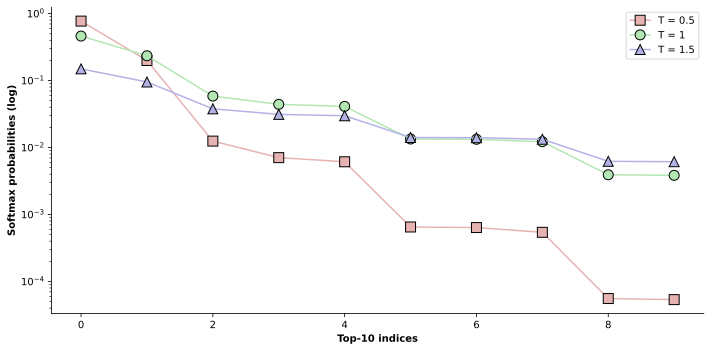

In [18]:
temps = [ .5,1,1.5 ]

plt.figure(figsize=(10,5))

shapes = 'so^'

for i,T in enumerate(temps):

  # calculate softmax and find the top 10
  sm = F.softmax(logits/T,dim=-1)
  top_k = torch.topk(sm,k)

  # plot
  color = [.7,.7,.7]
  color[i] = .9
  plt.plot(top_k.values,f'{shapes[i]}-',markerfacecolor=color,
           color=color,markeredgecolor='k',markersize=10,label=f'T = {T}')


plt.legend()
plt.gca().set(xlabel=f'Top-{k} indices',ylabel='Softmax probabilities (log)',yscale='log')

plt.tight_layout()
plt.savefig('ch4_proj16_part4.png')
plt.show()

# **Part 5: Numerical instabilities and normalization**

In [19]:
# get the outputs of the models
tokens = tokenizer.encode('A plethora of platypuses.',return_tensors='pt')
outputs_small = gpt2_small(tokens)
outputs_large = gpt2_large(tokens)

In [20]:
# grab the final token logit outputs
logits_small = outputs_small.logits[0,-1,:].detach()
logits_large = outputs_large.logits[0,-1,:].detach()

_,axs = plt.subplots(1,3,figsize=(12,3.5))

# gpt2 small
axs[0].plot(logits_small,'k.',alpha=.2)
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Output logits',title='A) GPT-2 SMALL')

# gpt2 large
axs[1].plot(logits_large,'k.',alpha=.2)
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Output logits',title='B) GPT-2 LARGE')

# against each other
axs[2].plot(logits_small,logits_large,'m.',alpha=.2)
axs[2].set(xlabel='GPT-2 SMALL',ylabel='GPT-2 LARGE',title='C) Comparison of both models')

plt.tight_layout()
plt.savefig('ch4_proj16_part5a.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [21]:
# manual softmax
sm_manual_small = torch.exp(logits_small) / torch.sum(torch.exp(logits_small))
sm_manual_large = torch.exp(logits_large) / torch.sum(torch.exp(logits_large))

_,axs = plt.subplots(1,3,figsize=(12,3.5))

# gpt2 small
axs[0].plot(sm_manual_small,'k.',alpha=.2)
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Softmax probabilities',title='A) GPT-2 SMALL')

# gpt2 large
axs[1].plot(sm_manual_large,'k.',alpha=.2)
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Softmax probabilities',title='B) GPT-2 LARGE')

# against each other
axs[2].plot(sm_manual_small,sm_manual_large,'m.',alpha=.2)
axs[2].set(xlabel='GPT-2 SMALL',ylabel='GPT-2 LARGE',title='C) Comparison of both models')

plt.tight_layout()
plt.savefig('ch4_proj16_part5b.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [22]:
logits_small[3000],sm_manual_small[1000]

(tensor(-115.9721), tensor(nan))

In [23]:
# simple normalization (subtract max value)
logits_small_norm = logits_small - logits_small.max()
logits_large_norm = logits_large - logits_large.max()

# visualize
_,axs = plt.subplots(1,3,figsize=(12,3.5))

# gpt2 small
axs[0].plot(logits_small_norm,'k.',alpha=.2)
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Raw logits (max-norm)',title='A) GPT-2 SMALL')

# gpt2 large
axs[1].plot(logits_large_norm,'k.',alpha=.2)
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Raw logits (max-norm)',title='B) GPT-2 LARGE')

# against each other
axs[2].plot(logits_small_norm,logits_large_norm,'m.',alpha=.2)
axs[2].set(xlabel='GPT-2 SMALL',ylabel='GPT-2 LARGE',title='C) Comparison of both models')

plt.tight_layout()
plt.savefig('ch4_proj16_part5c.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [24]:
# now repeat the manual softmax
sm_manual_smallN = torch.exp(logits_small_norm) / torch.sum(torch.exp(logits_small_norm))
sm_manual_largeN = torch.exp(logits_large_norm) / torch.sum(torch.exp(logits_large_norm))

_,axs = plt.subplots(1,3,figsize=(12,3.5))

# gpt2 small
axs[0].plot(sm_manual_smallN,'k.',alpha=.2)
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Softmax probabilities',title='A) GPT-2 SMALL')

# gpt2 large
axs[1].plot(sm_manual_largeN,'k.',alpha=.2)
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Softmax probabilities',title='B) GPT-2 LARGE')

# against each other
axs[2].plot(sm_manual_smallN,sm_manual_largeN,'m.',alpha=.2)
axs[2].set(xlabel='GPT-2 SMALL',ylabel='GPT-2 LARGE',title='C) Comparison of both models')

plt.tight_layout()
plt.savefig('ch4_proj16_part5d.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [25]:
# pytorch softmax
sm_torch_small = F.softmax(logits_small,dim=-1)
sm_torch_large = F.softmax(logits_large,dim=-1)

_,axs = plt.subplots(1,3,figsize=(12,3.5))

# gpt2 small
axs[0].plot(sm_torch_small,'k.',alpha=.2)
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Softmax probabilities',title='GPT-2 SMALL')

# gpt2 large
axs[1].plot(sm_torch_large,'k.',alpha=.2)
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',ylabel='Softmax probabilities',title='GPT-2 LARGE')

# against each other
axs[2].plot(sm_torch_small,sm_torch_large,'m.',alpha=.2)
axs[2].set(xlabel='GPT-2 SMALL',ylabel='GPT-2 LARGE',title='Comparison of both models')

plt.tight_layout()
plt.savefig('ch4_proj16_part5e.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.